<a href="https://colab.research.google.com/github/iherrec/2-DAW-Optativa/blob/main/Pr%C3%A1ctica_1_Teachable_Machine.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Práctica 1 - Teachable Machine - Iván Hernández Recio**

# Paso 1
Entrenamos la Teachable Machine. En mi caso he cargado 60 imágenes de cada clase que quiero que clasifique, que serán un ratón de ordenador y una botella.

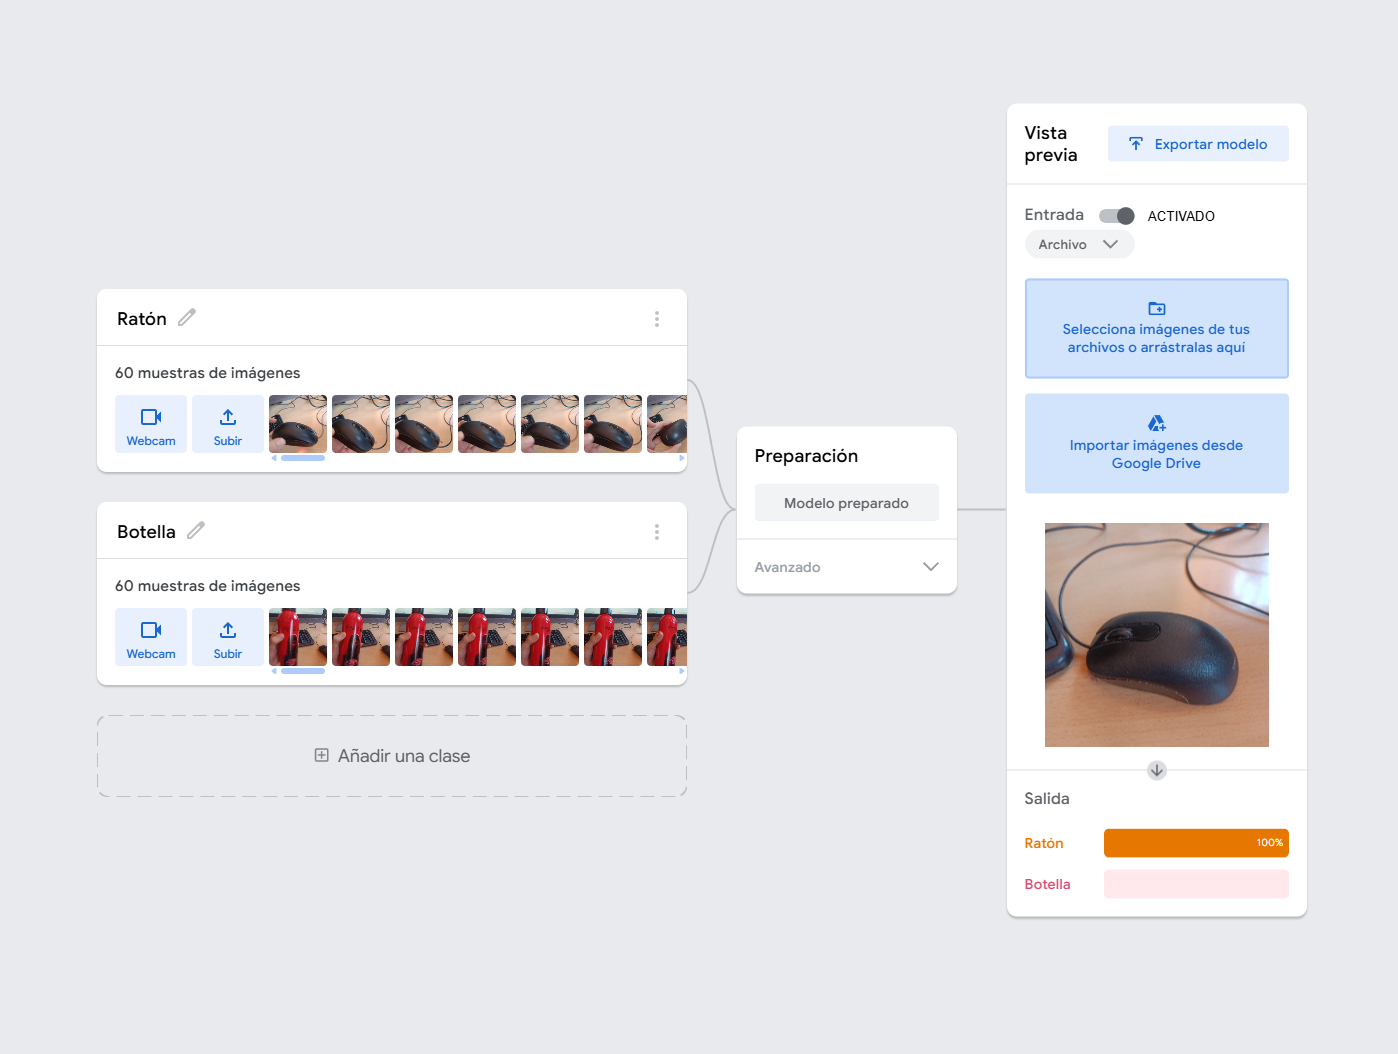

# Paso 2
Una vez comprobada la funcionalidad del modelo, lo exportamos en Tensorflow.js para su implementación en una web.

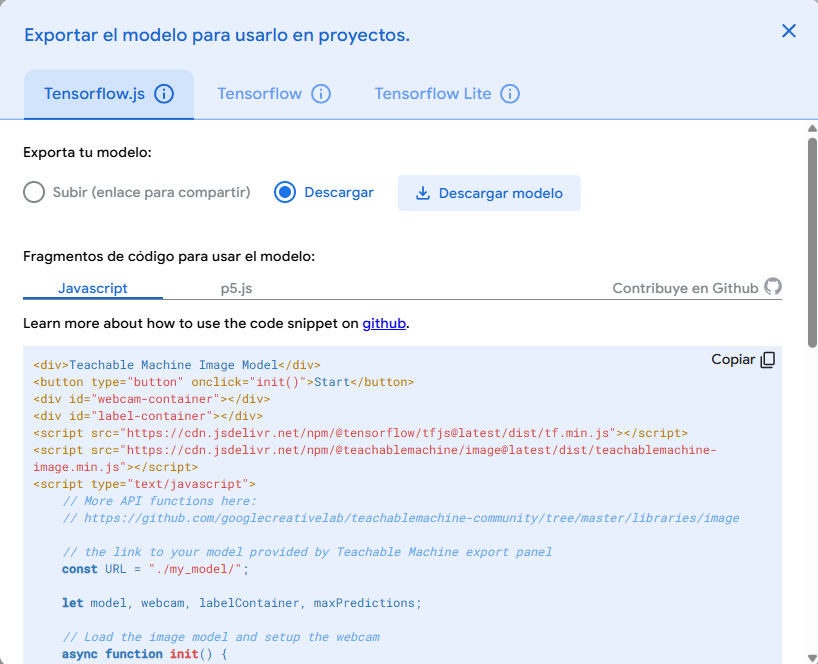

# Paso 3
Ya en Visual Studio Code, creamos un nuevo proyecto con un index.html, styles.css, app.js y la carpeta con los archivos del modelo.
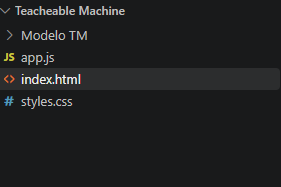

# Paso 4
Con la ayuda de Claude desarrollamos la app.
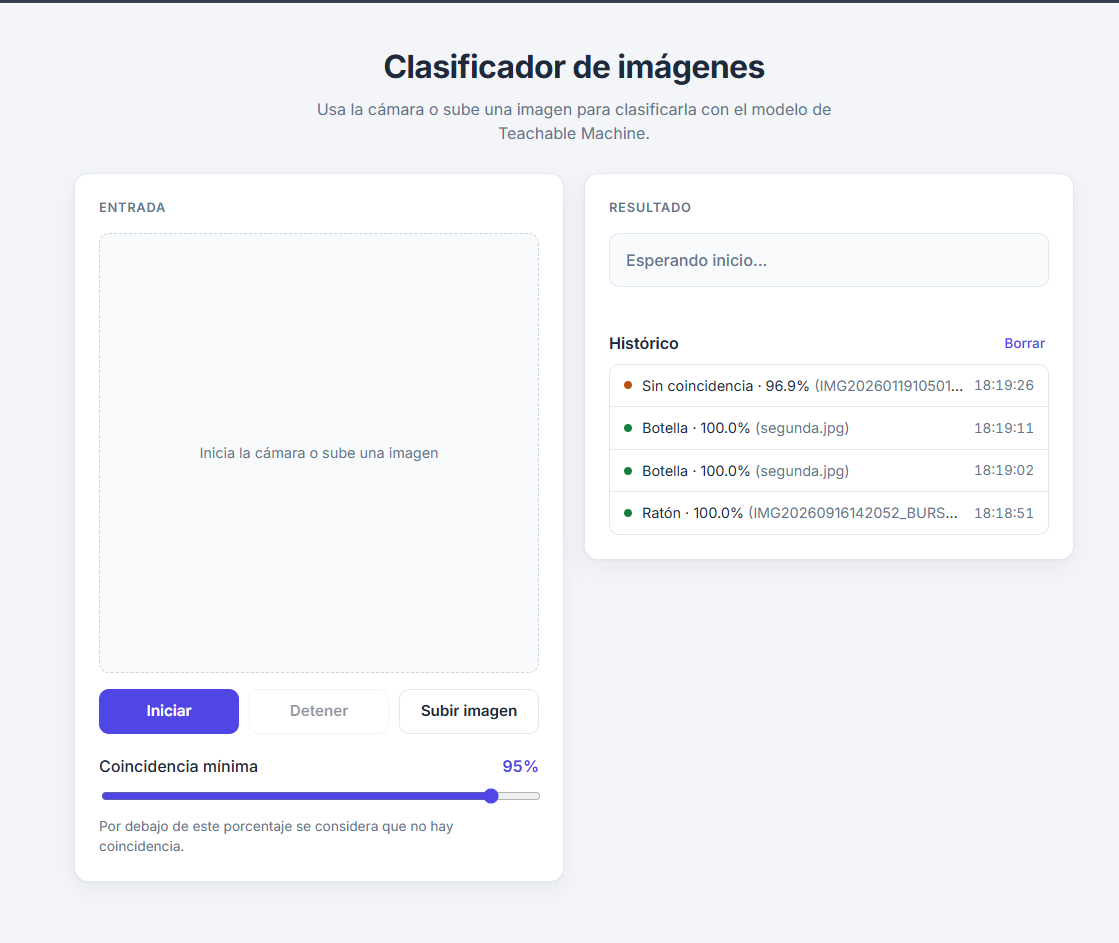

# Paso 5
Comprobamos la funcionalidad de la aplicación. Se puede elegir como entrada una webcam o subir imágenes en su defecto. Podemos controlar el umbral de coincidencia, haciéndolo más permisivo o menos.
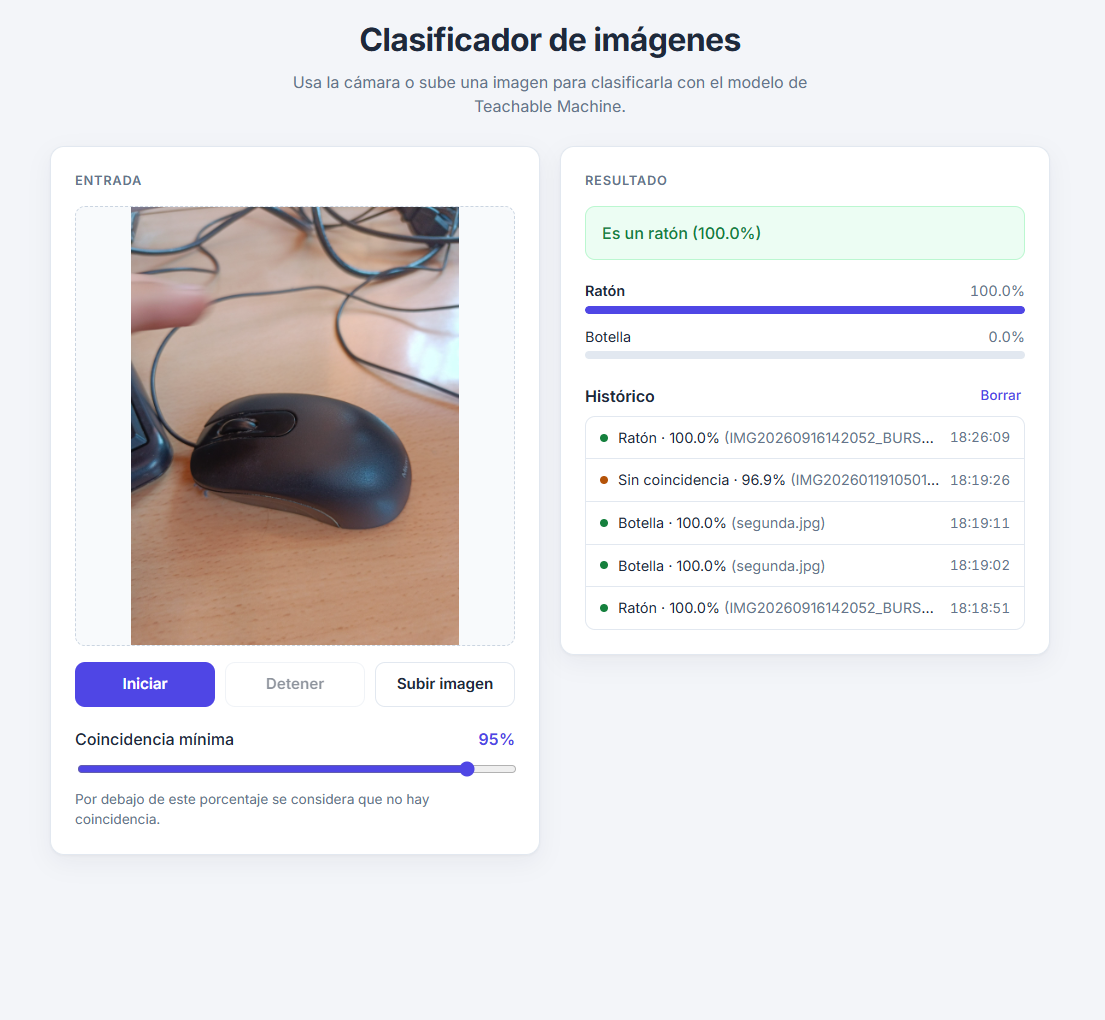

# Paso 6
En caso de que el archivo a comparar no supere el umbral de coincidencia, mostrará el siguiente mensaje. Todas las comparaciones quedan guardadas en un historial.
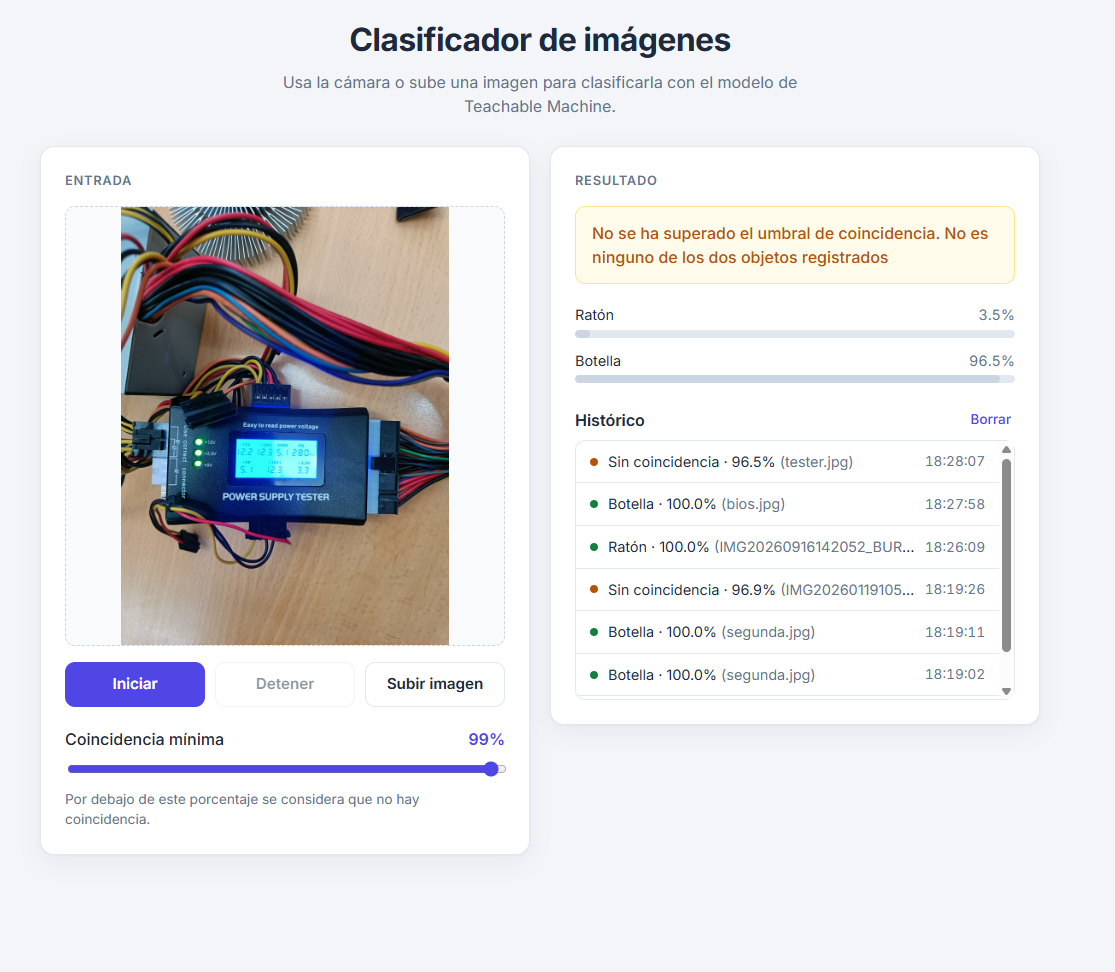

# Código HTML
<!DOCTYPE html>
<html lang="es">
<head>
  <meta charset="UTF-8">
  <meta name="viewport" content="width=device-width, initial-scale=1.0">
  <!-- <title>Clasificador Teachable Machine</title> -->
  <link rel="preconnect" href="https://fonts.googleapis.com">
  <link rel="preconnect" href="https://fonts.gstatic.com" crossorigin>
  <link href="https://fonts.googleapis.com/css2?family=Inter:wght@400;500;600;700&display=swap" rel="stylesheet">
  <link rel="stylesheet" href="styles.css">
  <!-- Versiones compatibles con los modelos exportados de Teachable Machine -->
  <script src="https://cdn.jsdelivr.net/npm/@tensorflow/tfjs@1.7.4/dist/tf.min.js"></script>
  <script src="https://cdn.jsdelivr.net/npm/@teachablemachine/image@0.8.5/dist/teachablemachine-image.min.js"></script>
</head>
<body>
  <main class="app">
    <header class="header">
      <h1>Clasificador de imágenes</h1>
      <p class="subtitle">Usa la cámara o sube una imagen para clasificarla con el modelo de Teachable Machine.</p>
    </header>

    <div class="layout">
      <!-- Columna izquierda: entrada -->
      <section class="card">
        <h2 class="card-title">Entrada</h2>

        <div class="viewer" id="viewer">
          <p class="viewer-placeholder" id="viewerPlaceholder">Inicia la cámara o sube una imagen</p>
          <div id="webcamContainer"></div>
          <img id="uploadedImage" alt="Imagen subida para clasificar" hidden>
        </div>

        <div class="actions">
          <button type="button" id="btnStart" class="btn btn-primary">Iniciar</button>
          <button type="button" id="btnStop" class="btn btn-secondary" disabled>Detener</button>
          <label class="btn btn-secondary btn-upload" for="imageUpload">Subir imagen</label>
          <input type="file" id="imageUpload" class="visually-hidden" accept="image/*">
        </div>

        <div class="field">
          <div class="field-header">
            <label for="threshold">Coincidencia mínima</label>
            <output id="thresholdValue" for="threshold">95%</output>
          </div>
          <input type="range" id="threshold" min="50" max="100" step="1" value="95">
          <p class="hint">Por debajo de este porcentaje se considera que no hay coincidencia.</p>
        </div>
      </section>

      <!-- Columna derecha: resultados -->
      <section class="card">
        <h2 class="card-title">Resultado</h2>

        <div id="message" class="message" role="status" aria-live="polite">Esperando inicio...</div>

        <div id="predictions" class="predictions"></div>

        <div class="history">
          <div class="history-header">
            <h3>Histórico</h3>
            <button type="button" id="btnClearHistory" class="btn-link">Borrar</button>
          </div>
          <ul id="historyList" class="history-list"></ul>
        </div>
      </section>
    </div>
  </main>

  <script src="app.js"></script>
</body>
</html>


# Código CSS
:root {
  --bg: #f3f5f9;
  --surface: #ffffff;
  --surface-alt: #f8fafc;
  --border: #e2e8f0;
  --border-strong: #cbd5e1;
  --text: #1e293b;
  --text-muted: #64748b;
  --primary: #4f46e5;
  --primary-hover: #4338ca;
  --primary-soft: #eef2ff;
  --success: #15803d;
  --success-soft: #ecfdf3;
  --success-border: #bbf7d0;
  --warning: #b45309;
  --warning-soft: #fffbeb;
  --warning-border: #fde68a;
  --error: #b91c1c;
  --error-soft: #fef2f2;
  --error-border: #fecaca;
  --radius: 14px;
  --radius-sm: 10px;
}

* {
  box-sizing: border-box;
}

[hidden] {
  display: none !important;
}

body {
  margin: 0;
  min-height: 100vh;
  background: var(--bg);
  color: var(--text);
  font-family: "Inter", system-ui, -apple-system, "Segoe UI", Roboto, Arial, sans-serif;
  line-height: 1.5;
}

.app {
  max-width: 1040px;
  margin: 0 auto;
  padding: 40px 20px;
}

/* Cabecera */
.header {
  text-align: center;
  margin-bottom: 28px;
}

.header h1 {
  margin: 0 0 6px;
  font-size: clamp(1.5rem, 4vw, 2rem);
  font-weight: 700;
  letter-spacing: -0.02em;
}

.subtitle {
  margin: 0 auto;
  max-width: 520px;
  color: var(--text-muted);
}

/* Distribución en dos columnas */
.layout {
  display: grid;
  grid-template-columns: repeat(2, minmax(0, 1fr));
  gap: 20px;
  align-items: start;
}

.card {
  background: var(--surface);
  border: 1px solid var(--border);
  border-radius: var(--radius);
  padding: 24px;
  box-shadow: 0 1px 2px rgba(15, 23, 42, 0.04), 0 8px 24px rgba(15, 23, 42, 0.05);
}

.card-title {
  margin: 0 0 16px;
  font-size: 0.8rem;
  font-weight: 600;
  text-transform: uppercase;
  letter-spacing: 0.06em;
  color: var(--text-muted);
}

/* Visor */
.viewer {
  position: relative;
  display: flex;
  align-items: center;
  justify-content: center;
  aspect-ratio: 1 / 1;
  overflow: hidden;
  background: var(--surface-alt);
  border: 1px dashed var(--border-strong);
  border-radius: var(--radius-sm);
}

.viewer-placeholder {
  margin: 0;
  padding: 20px;
  color: var(--text-muted);
  font-size: 0.9rem;
  text-align: center;
}

#webcamContainer:empty {
  display: none;
}

#webcamContainer canvas,
#uploadedImage {
  display: block;
  width: 100%;
  height: 100%;
  object-fit: contain;
}

/* Botones */
.actions {
  display: flex;
  flex-wrap: wrap;
  gap: 10px;
  margin: 16px 0 20px;
}

.btn {
  flex: 1 1 0;
  display: inline-flex;
  align-items: center;
  justify-content: center;
  min-width: 110px;
  padding: 10px 16px;
  border: 1px solid transparent;
  border-radius: var(--radius-sm);
  font: inherit;
  font-size: 0.95rem;
  font-weight: 600;
  cursor: pointer;
  user-select: none;
  transition: background-color 0.2s, border-color 0.2s, opacity 0.2s;
}

.btn-primary {
  background: var(--primary);
  color: #fff;
}

.btn-primary:hover:not(:disabled) {
  background: var(--primary-hover);
}

.btn-secondary {
  background: var(--surface);
  border-color: var(--border);
  color: var(--text);
}

.btn-secondary:hover:not(:disabled) {
  background: var(--surface-alt);
  border-color: var(--border-strong);
}

.btn:disabled {
  opacity: 0.5;
  cursor: not-allowed;
}

.btn-link {
  padding: 2px 4px;
  border: none;
  background: none;
  color: var(--primary);
  font: inherit;
  font-size: 0.85rem;
  font-weight: 500;
  cursor: pointer;
}

.btn-link:hover {
  text-decoration: underline;
}

.btn:focus-visible,
.btn-link:focus-visible,
input[type="range"]:focus-visible {
  outline: 2px solid var(--primary);
  outline-offset: 2px;
}

/* El input de archivo queda oculto pero accesible; al enfocarlo se marca su etiqueta */
.visually-hidden {
  position: absolute;
  width: 1px;
  height: 1px;
  overflow: hidden;
  clip: rect(0 0 0 0);
  white-space: nowrap;
}


.btn-upload:has(+ .visually-hidden:focus-visible) {
  outline: 2px solid var(--primary);
  outline-offset: 2px;
}

/* Umbral */
.field-header {
  display: flex;
  justify-content: space-between;
  align-items: baseline;
  margin-bottom: 8px;
}

.field-header label {
  font-weight: 500;
}

.field-header output {
  font-weight: 600;
  color: var(--primary);
  font-variant-numeric: tabular-nums;
}

input[type="range"] {
  width: 100%;
  accent-color: var(--primary);
}

.hint {
  margin: 6px 0 0;
  font-size: 0.85rem;
  color: var(--text-muted);
}

/* Mensaje de salida */
.message {
  padding: 14px 16px;
  margin-bottom: 20px;
  background: var(--surface-alt);
  border: 1px solid var(--border);
  border-radius: var(--radius-sm);
  color: var(--text-muted);
  font-weight: 500;
  transition: background-color 0.2s, border-color 0.2s, color 0.2s;
}

.message.success {
  background: var(--success-soft);
  border-color: var(--success-border);
  color: var(--success);
}

.message.warning {
  background: var(--warning-soft);
  border-color: var(--warning-border);
  color: var(--warning);
}

.message.error {
  background: var(--error-soft);
  border-color: var(--error-border);
  color: var(--error);
}

/* Barras de predicción */
.predictions {
  display: flex;
  flex-direction: column;
  gap: 12px;
}

.prediction-header {
  display: flex;
  justify-content: space-between;
  margin-bottom: 4px;
  font-size: 0.9rem;
}

.prediction-value {
  color: var(--text-muted);
  font-variant-numeric: tabular-nums;
}

.prediction-bar {
  height: 8px;
  background: var(--border);
  border-radius: 999px;
  overflow: hidden;
}

.prediction-fill {
  height: 100%;
  width: 0;
  background: var(--border-strong);
  border-radius: 999px;
  transition: width 0.2s ease-out, background-color 0.2s;
}

.prediction.is-match .prediction-fill {
  background: var(--primary);
}

.prediction.is-match .prediction-name {
  font-weight: 600;
}

/* Histórico */
.history {
  margin-top: 24px;
}

.history-header {
  display: flex;
  justify-content: space-between;
  align-items: center;
  margin-bottom: 8px;
}

.history-header h3 {
  margin: 0;
  font-size: 1rem;
  font-weight: 600;
}

.history-list {
  list-style: none;
  margin: 0;
  padding: 0;
  max-height: 260px;
  overflow-y: auto;
  border: 1px solid var(--border);
  border-radius: var(--radius-sm);
}

.history-list:empty::before {
  content: "Aún no hay resultados.";
  display: block;
  padding: 12px 14px;
  color: var(--text-muted);
  font-size: 0.9rem;
}

.history-list li {
  display: grid;
  grid-template-columns: auto 1fr auto;
  align-items: center;
  gap: 10px;
  padding: 10px 14px;
  font-size: 0.9rem;
  border-bottom: 1px solid var(--border);
}

.history-list li:last-child {
  border-bottom: none;
}

.history-dot {
  width: 8px;
  height: 8px;
  border-radius: 50%;
  background: var(--warning);
}

.history-list li.is-match .history-dot {
  background: var(--success);
}

.history-text {
  min-width: 0;
  overflow: hidden;
  text-overflow: ellipsis;
  white-space: nowrap;
}

.history-source {
  color: var(--text-muted);
}

.history-time {
  color: var(--text-muted);
  font-size: 0.85rem;
  font-variant-numeric: tabular-nums;
}

/* Responsive */
@media (max-width: 820px) {
  .layout {
    grid-template-columns: 1fr;
  }

  .viewer {
    max-width: 420px;
    margin: 0 auto;
    width: 100%;
  }
}

@media (max-width: 480px) {
  .app {
    padding: 24px 16px;
  }

  .card {
    padding: 18px;
  }

  .btn {
    flex-basis: 100%;
  }
}


# Código JavaScript
// Carpeta del modelo exportado desde Teachable Machine
const MODEL_URL = "./Modelo TM/";

// Mensajes personalizados de salida
const CLASS_MESSAGES = {
  "Ratón": "Es un ratón",
  "Botella": "Es una botella",
};
const NO_MATCH_MESSAGE =
  "No se ha superado el umbral de coincidencia. No es ninguno de los dos objetos registrados";

// Fotogramas seguidos con el mismo resultado antes de guardarlo en el histórico (evita parpadeos)
const STABLE_FRAMES = 15;
const HISTORY_KEY = "tm-historico";
const HISTORY_LIMIT = 50;
const MODEL_SIZE = 224;

const els = {
  btnStart: document.getElementById("btnStart"),
  btnStop: document.getElementById("btnStop"),
  imageUpload: document.getElementById("imageUpload"),
  threshold: document.getElementById("threshold"),
  thresholdValue: document.getElementById("thresholdValue"),
  placeholder: document.getElementById("viewerPlaceholder"),
  webcamContainer: document.getElementById("webcamContainer"),
  uploadedImage: document.getElementById("uploadedImage"),
  message: document.getElementById("message"),
  predictions: document.getElementById("predictions"),
  historyList: document.getElementById("historyList"),
  btnClearHistory: document.getElementById("btnClearHistory"),
};

let model = null;
let modelLoading = null;
let webcam = null;
let running = false;
let animationId = null;

// Control de estabilidad para el histórico de la cámara
let candidateKey = null;
let candidateCount = 0;
let lastSavedKey = null;

let history = loadHistory();

// ---------- Modelo ----------

function loadModel() {
  if (model) return Promise.resolve(model);
  if (!modelLoading) {
    setMessage("Cargando modelo...");
    modelLoading = tmImage
      .load(MODEL_URL + "model.json", MODEL_URL + "metadata.json")
      .then((loaded) => {
        model = loaded;
        buildPredictionList(model.getClassLabels());
        return model;
      })
      .catch((err) => {
        modelLoading = null;
        throw err;
      });
  }
  return modelLoading;
}

function getThreshold() {
  return Number(els.threshold.value) / 100;
}

// Clasifica una imagen/canvas y devuelve la clase con mayor probabilidad
async function classify(source) {
  const predictions = await model.predict(source);
  const best = predictions.reduce((a, b) => (b.probability > a.probability ? b : a));
  const result = {
    className: best.className,
    probability: best.probability,
    match: best.probability >= getThreshold(),
  };
  updatePredictionList(predictions, result);
  return result;
}

// ---------- Cámara ----------

async function startCamera() {
  els.btnStart.disabled = true;
  try {
    await loadModel();
    webcam = new tmImage.Webcam(400, 400, true);
    await webcam.setup();
    await webcam.play();
  } catch (err) {
    if (webcam) webcam.stop();
    webcam = null;
    els.btnStart.disabled = false;
    showError(err);
    return;
  }

  els.uploadedImage.hidden = true;
  els.placeholder.hidden = true;
  els.webcamContainer.replaceChildren(webcam.canvas);

  running = true;
  candidateKey = null;
  candidateCount = 0;
  lastSavedKey = null;
  els.btnStop.disabled = false;
  setMessage("Analizando...");
  animationId = requestAnimationFrame(loop);
}

async function loop() {
  if (!running) return;
  webcam.update();
  const result = await classify(webcam.canvas);
  if (!running) return; // se detuvo mientras se predecía

  showResult(result);
  trackWebcamResult(result);
  animationId = requestAnimationFrame(loop);
}

function stopCamera() {
  if (!running && !webcam) return;
  running = false;
  cancelAnimationFrame(animationId);
  if (webcam) webcam.stop();
  webcam = null;
  els.btnStart.disabled = false;
  els.btnStop.disabled = true;
  setMessage("Cámara detenida.");
}

// Solo guarda un resultado de la cámara cuando se mantiene estable y cambia respecto al último
function trackWebcamResult(result) {
  const key = result.match ? result.className : "__sin_coincidencia__";
  if (key === candidateKey) {
    candidateCount++;
  } else {
    candidateKey = key;
    candidateCount = 1;
  }
  if (candidateCount === STABLE_FRAMES && key !== lastSavedKey) {
    lastSavedKey = key;
    addHistory(result, "Cámara");
  }
}

// ---------- Imagen subida ----------

async function handleImageUpload(event) {
  const file = event.target.files[0];
  event.target.value = ""; // permite volver a subir la misma imagen
  if (!file) return;

  stopCamera();

  try {
    await loadModel();
    const img = await loadImage(file);

    els.webcamContainer.replaceChildren();
    els.placeholder.hidden = true;
    els.uploadedImage.src = img.src;
    els.uploadedImage.hidden = false;

    const result = await classify(toModelCanvas(img));
    showResult(result);
    addHistory(result, file.name);
  } catch (err) {
    showError(err);
  }
}

function loadImage(file) {
  return new Promise((resolve, reject) => {
    const img = new Image();
    img.onload = () => resolve(img);
    img.onerror = () => reject(new Error("No se ha podido leer la imagen."));
    img.src = URL.createObjectURL(file);
  });
}

// Recorta la imagen al cuadrado central a su tamaño real, como hace Teachable Machine
function toModelCanvas(img) {
  const size = Math.min(img.naturalWidth, img.naturalHeight);
  const canvas = document.createElement("canvas");
  canvas.width = MODEL_SIZE;
  canvas.height = MODEL_SIZE;
  canvas.getContext("2d").drawImage(
    img,
    (img.naturalWidth - size) / 2,
    (img.naturalHeight - size) / 2,
    size,
    size,
    0,
    0,
    MODEL_SIZE,
    MODEL_SIZE
  );
  return canvas;
}

// ---------- Interfaz ----------

function setMessage(text, type = "") {
  els.message.textContent = text;
  els.message.className = type ? `message ${type}` : "message";
}

function showResult(result) {
  if (result.match) {
    const text = CLASS_MESSAGES[result.className] || `Coincidencia: ${result.className}`;
    setMessage(`${text} (${formatPercent(result.probability)})`, "success");
  } else {
    setMessage(NO_MATCH_MESSAGE, "warning");
  }
}

function showError(err) {
  console.error(err);
  let text = "Ha ocurrido un error: " + (err && err.message ? err.message : err);
  if (err && (err.name === "NotAllowedError" || err.name === "SecurityError")) {
    text = "No se ha dado permiso para usar la cámara.";
  } else if (err && err.name === "NotFoundError") {
    text = "No se ha encontrado ninguna cámara.";
  } else if (location.protocol === "file:") {
    text = "No se puede cargar el modelo abriendo el archivo directamente. Abre la página con un servidor local (por ejemplo, Live Server).";
  }
  setMessage(text, "error");
}

function buildPredictionList(labels) {
  els.predictions.replaceChildren(
    ...labels.map((label) => {
      const item = document.createElement("div");
      item.className = "prediction";
      item.innerHTML = `
        <div class="prediction-header">
          <span class="prediction-name"></span>
          <span class="prediction-value">0.0%</span>
        </div>
        <div class="prediction-bar"><div class="prediction-fill"></div></div>
      `;
      item.querySelector(".prediction-name").textContent = label;
      return item;
    })
  );
}

function updatePredictionList(predictions, result) {
  predictions.forEach((p, i) => {
    const item = els.predictions.children[i];
    if (!item) return;
    item.classList.toggle("is-match", result.match && p.className === result.className);
    item.querySelector(".prediction-value").textContent = formatPercent(p.probability);
    item.querySelector(".prediction-fill").style.width = `${p.probability * 100}%`;
  });
}

function formatPercent(probability) {
  return `${(probability * 100).toFixed(1)}%`;
}

// ---------- Histórico ----------

function loadHistory() {
  try {
    return JSON.parse(localStorage.getItem(HISTORY_KEY)) || [];
  } catch {
    return [];
  }
}

function saveHistory() {
  try {
    localStorage.setItem(HISTORY_KEY, JSON.stringify(history));
  } catch {
    // Si no hay almacenamiento disponible, el histórico se mantiene solo en esta sesión
  }
}

function addHistory(result, source) {
  history.unshift({
    className: result.className,
    probability: result.probability,
    match: result.match,
    source,
    time: new Date().toISOString(),
  });
  history = history.slice(0, HISTORY_LIMIT);
  saveHistory();
  renderHistory();
}

function renderHistory() {
  els.historyList.replaceChildren(
    ...history.map((entry) => {
      const li = document.createElement("li");
      li.classList.toggle("is-match", entry.match);

      const dot = document.createElement("span");
      dot.className = "history-dot";

      const text = document.createElement("span");
      text.className = "history-text";
      const label = entry.match ? entry.className : "Sin coincidencia";
      text.textContent = `${label} · ${formatPercent(entry.probability)} `;
      const source = document.createElement("span");
      source.className = "history-source";
      source.textContent = `(${entry.source})`;
      text.append(source);
      text.title = text.textContent;

      const time = document.createElement("span");
      time.className = "history-time";
      time.textContent = new Date(entry.time).toLocaleTimeString();

      li.append(dot, text, time);
      return li;
    })
  );
}

function clearHistory() {
  history = [];
  saveHistory();
  renderHistory();
}

// ---------- Eventos ----------

els.btnStart.addEventListener("click", startCamera);
els.btnStop.addEventListener("click", stopCamera);
els.imageUpload.addEventListener("change", handleImageUpload);
els.btnClearHistory.addEventListener("click", clearHistory);
els.threshold.addEventListener("input", () => {
  els.thresholdValue.textContent = `${els.threshold.value}%`;
});

renderHistory();

if (location.protocol === "file:") {
  setMessage(
    "Abre la página con un servidor local (por ejemplo, Live Server) para poder cargar el modelo.",
    "error"
  );
}
